## Écart entre rendements déclarés et mesures par coupe

Ce notebook exécute l'étude préenregistrée dans `docs/research_cropcut_gap.md`, issue de la quatrième suggestion de la revue du projet par une mentore experte. Sur les mesures par coupe des grappes tenues à l'écart, le modèle de `survey` ne bat la référence que de 1 %, avec un biais logarithmique de 0,333. L'étude cherche si cette limite vient d'une différence entre deux méthodes de mesure, que le modèle reproduit, et si une correction apprise sur les grappes vues la réduit.

**Précautions**

- Le plan a été versionné avant tout calcul, puis le choix des corrections a été figé dans `src/recherche/ecart_cropcut.py` avant la lecture des grappes tenues à l'écart.
- Seul le développement de `survey` est consulté. `cropcut` ne sert qu'à apprendre une correction appliquée après la prédiction.
- Les calculs sont faits par `python -m src.recherche.ecart_cropcut calibration` puis `finale`. Ce notebook relit leurs résultats.

In [1]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

RACINE = Path.cwd().parent
sys.path.insert(0, str(RACINE))

from src.recherche.ecart_cropcut import (
    DOSSIER_RECHERCHE, METHODE_RETENUE, ajuster, bilan_final, bilan_mesures, choisir, lire_calibration, oracle_declare,
)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
cellules, calibration, choix = lire_calibration()
finale = pd.read_csv(DOSSIER_RECHERCHE / "cropcut_finale.csv.gz")
mesures = bilan_mesures(cellules)
tableau, hypotheses = bilan_final(finale)

### 1. Tests unitaires

Les tests de l'étude vérifient l'appariement des cellules, les intervalles bootstrap, les quatre corrections, le repli du décalage par culture et la règle de choix.

In [2]:
execution = subprocess.run(
    [sys.executable, "-m", "unittest", "discover", "-s", "tests", "-t", "."],
    cwd=RACINE, capture_output=True, text=True,
)
print(execution.stderr.strip().splitlines()[-3:])

['Ran 121 tests in 29.322s', '', 'OK']


### 2. Données de l'étude

In [3]:
print("Mesures de calibration, grappes vues :", len(calibration))
print("Groupes de calibration :", calibration["groupe"].nunique())
print("Cellules appariées :", len(cellules), "dont", int(cellules["mesures"].sum()), "mesures et",
      int(cellules["parcelles"].sum()), "parcelles déclarées")
print("Mesures des grappes tenues à l'écart :", len(finale), "dans", finale["groupe"].nunique(), "groupes")

Mesures de calibration, grappes vues : 8884
Groupes de calibration : 397
Cellules appariées : 2071 dont 6490 mesures et 15539 parcelles déclarées
Mesures des grappes tenues à l'écart : 2297 dans 97 groupes


**Constat**

- L'ensemble de calibration compte 8 884 mesures par coupe des grappes vues. Les 82 mesures sans coordonnées, qui n'ont ni grappe ni groupe, en ont été écartées, ce que le plan n'avait pas prévu.
- 2 071 cellules, formées de la grappe, de la culture et de l'année, figurent à la fois dans `cropcut` et dans le développement de `survey`.
- L'évaluation finale porte sur les 2 297 mesures des grappes tenues à l'écart, inchangées depuis `docs/evaluation.md`.

### 3. Comparaison des deux mesures

L'écart d'une cellule est la moyenne du logarithme du rendement déclaré diminuée de celle du rendement mesuré par coupe. Il est positif quand la déclaration dépasse la mesure. Les intervalles de confiance à 95 % sont obtenus par bootstrap des groupes du protocole, avec 2 000 tirages.

In [4]:
display(mesures.round(3))
print("Rapport des moyennes géométriques, toutes cellules :", round(float(np.exp(mesures.loc["toutes", "ecart"])), 2))

,cellules,ecart,bas,haut
strate,,,,
toutes,2071,0.262,0.206,0.315
surface_petites,691,0.490,0.406,0.571
surface_moyennes,690,0.224,0.151,0.299
surface_grandes,690,0.070,-0.012,0.154
culture_Maize,391,0.232,0.151,0.323
culture_Teff,316,0.120,0.026,0.206
culture_Sorghum,307,0.211,0.120,0.306
culture_Beans,293,0.316,0.219,0.405
culture_Barley,246,0.435,0.337,0.536


Rapport des moyennes géométriques, toutes cellules : 1.3


**Constat**

- Sur les mêmes grappes, cultures et années, le rendement déclaré dépasse la mesure par coupe de 0,262 en logarithme, soit d'environ 30 %, avec un intervalle de 0,206 à 0,315.
- L'écart décroît avec la taille des parcelles. Il vaut 0,490 dans le tiers des cellules aux plus petites parcelles, soit environ 63 %, 0,224 dans le tiers intermédiaire, et 0,070 dans le tiers aux plus grandes, sans y être significatif.
- La différence entre petites et grandes parcelles vaut 0,420, avec un intervalle de 0,311 à 0,536.
- L'écart est positif pour les sept cultures étudiées, de 0,120 pour le teff à 0,435 pour l'orge.

**Analyse**

Le résultat reproduit celui de Desiere et Jolliffe sur les mêmes enquêtes éthiopiennes. La déclaration surestime surtout la récolte des petites parcelles, où une même erreur sur la production pèse davantage rapportée à une petite surface. Le biais du modèle sur `cropcut` n'est donc pas d'abord un défaut du modèle. Il hérite de la cible qu'il apprend.

### 4. Part de l'erreur imposée par la différence de méthode

À titre descriptif, chaque mesure par coupe d'une cellule appariée est prédite par la moyenne géométrique des rendements déclarés de sa cellule, comme si le modèle connaissait parfaitement les déclarations du même lieu, de la même culture et de la même saison.

In [5]:
display(oracle_declare(cellules, calibration).round(3).to_frame("valeur"))

,valeur
mesures,6490.000
mae_log_declare_cellule,0.733
mae_log_modele_hors_pli,0.656
mae_log_reference_hors_pli,0.717


**Constat**

Sur les 6 490 mesures des cellules appariées, la moyenne déclarée de la cellule atteint une erreur `mae_log` de 0,733, contre 0,656 pour le modèle hors pli et 0,717 pour la référence hors pli.

**Analyse**

Même une connaissance parfaite des déclarations de la cellule prédit moins bien la mesure par coupe que le modèle. L'erreur sur `cropcut` provient donc surtout de l'écart entre méthodes et de la variabilité d'une parcelle à l'autre au sein d'une grappe. Un meilleur modèle du rendement déclaré ne peut pas la faire disparaître.

### 5. Choix des corrections

Chaque correction est évaluée par validation croisée à cinq plis groupés sur l'ensemble de calibration, à partir des prédictions hors pli. La règle retient la méthode la plus simple dont l'erreur ne dépasse pas la meilleure de plus de 0,005.

In [6]:
display(choix.round(4))
print("Choix de la règle :", {nom: choisir(choix[nom]) for nom in choix})
print("Choix gelés avant l'évaluation finale :", METHODE_RETENUE)
print("Correction du modèle :", ajuster("C2", np.log(calibration["prediction"]), np.log(calibration["Yield_ton_ha_"]),
                                       calibration["Crop"]))
print("Correction de la référence :", ajuster("C3", np.log(calibration["reference"]), np.log(calibration["Yield_ton_ha_"]),
                                             calibration["Crop"]))

,modele,reference
C0,0.6605,0.7114
C1,0.6318,0.7024
C2,0.6268,0.6985
C3,0.6264,0.6603


Choix de la règle : {'modele': 'C2', 'reference': 'C3'}
Choix gelés avant l'évaluation finale : {'modele': 'C2', 'reference': 'C3'}


Correction du modèle : {'decalage': -0.24310565238612597, 'par_culture': {'Barley': -0.4166463041522158, 'Beans': -0.22356975546206823, 'Groundnut': -0.7782106523749895, 'Maize': -0.22633298441183825, 'Millet': -0.10232926866423801, 'Sesame': -0.3420988515248084, 'Sorghum': -0.22767206827461517, 'Teff': -0.1391175729166975, 'Wheat': -0.3073012218761313}}
Correction de la référence : {'pente': 0.37060962444597884, 'ordonnee': -0.18689275748913586}


**Constat**

- Pour le modèle, l'erreur croisée passe de 0,6605 sans correction à 0,6318 avec un décalage unique, 0,6268 avec un décalage par culture et 0,6264 avec une droite de recalibration. La règle retient le décalage par culture, C2, à moins de 0,005 de la meilleure.
- Le décalage global vaut -0,243. Par culture, il va de -0,102 pour le mil à -0,778 pour l'arachide.
- Pour la référence, la droite de recalibration, C3, l'emporte nettement, avec 0,6603 contre 0,7114 sans correction. Sa pente de 0,371 resserre fortement les prédictions vers la moyenne.

**Analyse**

Le modèle a surtout besoin d'un décalage de niveau. La référence, moyenne des déclarations de la grappe, a en plus besoin d'être fortement atténuée, car la moyenne déclarée d'une grappe prédit mal la mesure d'une parcelle, comme le montre la section 4.

### 6. Évaluation finale

Les corrections gelées sont estimées sur tout l'ensemble de calibration, puis appliquées une seule fois aux prédictions finales du modèle et de la référence sur les grappes tenues à l'écart.

In [7]:
display(tableau.round(3))
display(hypotheses.round(4))

,mesures,mae_log,mae_log_reference,competence,biais_log
brut,2297.0,0.669,0.676,0.011,0.333
corrige,2297.0,0.625,0.635,0.016,0.083


,moyenne,bas,haut
H3_gain_correction,0.0433,0.0185,0.0701
H4_avance_sur_reference,0.0099,-0.0191,0.0377


**Constat**

- Après correction, l'erreur `mae_log` du modèle passe de 0,669 à 0,625. Le gain vaut 0,043, avec un intervalle de 0,019 à 0,070.
- Le biais logarithmique passe de 0,333 à 0,083. Il reste positif, car l'écart des grappes tenues à l'écart dépasse celui de la calibration.
- La référence corrigée passe de 0,676 à 0,635. Le modèle corrigé la bat de 0,010, avec un intervalle de -0,019 à 0,038, soit une compétence de 1,6 %.

**Analyse**

La correction transpose aux grappes jamais vues l'essentiel du décalage appris sur les grappes vues, et ramène le biais au quart de sa valeur. Elle profite autant à la référence qu'au modèle, si bien que l'avance du modèle reste négligeable. À l'échelle de la parcelle mesurée par coupe, les variables du modèle n'apportent presque rien au-delà de la moyenne locale.

### 7. Verdict des hypothèses

In [8]:
verdicts = pd.DataFrame([
    {"hypothese": "H1", "mesure": mesures.loc["toutes", "ecart"], "bas": mesures.loc["toutes", "bas"],
     "haut": mesures.loc["toutes", "haut"]},
    {"hypothese": "H2", "mesure": mesures.loc["petites_moins_grandes", "ecart"],
     "bas": mesures.loc["petites_moins_grandes", "bas"], "haut": mesures.loc["petites_moins_grandes", "haut"]},
    {"hypothese": "H3", "mesure": hypotheses.loc["H3_gain_correction", "moyenne"],
     "bas": hypotheses.loc["H3_gain_correction", "bas"], "haut": hypotheses.loc["H3_gain_correction", "haut"]},
    {"hypothese": "H4", "mesure": hypotheses.loc["H4_avance_sur_reference", "moyenne"],
     "bas": hypotheses.loc["H4_avance_sur_reference", "bas"], "haut": hypotheses.loc["H4_avance_sur_reference", "haut"]},
]).set_index("hypothese")
verdicts["confirmee"] = verdicts["bas"] > 0
display(verdicts.round(4))

,mesure,bas,haut,confirmee
hypothese,,,,
H1,0.2616,0.2061,0.3152,True
H2,0.4196,0.3109,0.5360,True
H3,0.0433,0.0185,0.0701,True
H4,0.0099,-0.0191,0.0377,False


**Constat**

- **H1 est confirmée.** Les rendements déclarés dépassent les mesures par coupe des mêmes cellules de 0,262.
- **H2 est confirmée.** L'écart des petites parcelles dépasse celui des grandes de 0,420.
- **H3 est confirmée.** La correction par culture réduit l'erreur du modèle de 0,043 sur les grappes tenues à l'écart.
- **H4 est réfutée.** Après correction, le modèle ne bat pas significativement la référence corrigée.

### 8. Figure

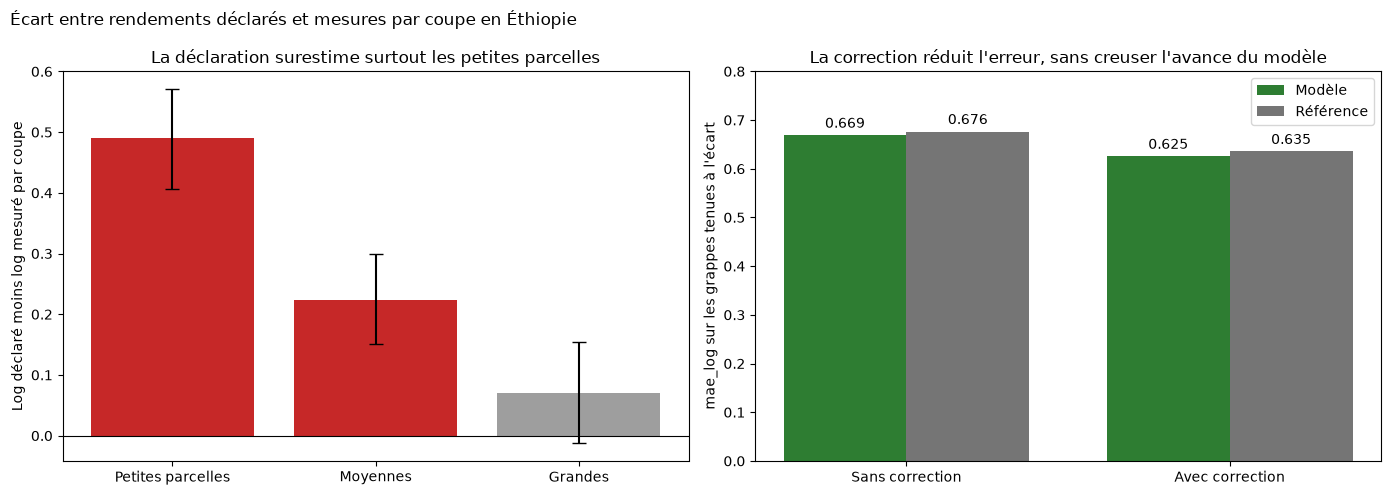

In [9]:
ordre = ["surface_petites", "surface_moyennes", "surface_grandes"]
figure, (gauche, droite) = plt.subplots(1, 2, figsize=(14, 5))
valeurs = mesures.loc[ordre]
x = np.arange(len(ordre))
gauche.bar(x, valeurs["ecart"], color=np.where(valeurs["bas"] > 0, "#c62828", "#9e9e9e"))
gauche.errorbar(x, valeurs["ecart"], yerr=[valeurs["ecart"] - valeurs["bas"], valeurs["haut"] - valeurs["ecart"]],
                fmt="none", ecolor="black", capsize=5)
gauche.axhline(0, color="black", lw=0.8)
gauche.set_xticks(x, ["Petites parcelles", "Moyennes", "Grandes"])
gauche.set_ylabel("Log déclaré moins log mesuré par coupe")
gauche.set_title("La déclaration surestime surtout les petites parcelles")
positions = np.arange(2)
largeur = 0.38
for decalage, (nom, couleur) in zip([-largeur / 2, largeur / 2], [("modele", "#2e7d32"), ("reference", "#757575")]):
    colonne = "mae_log" if nom == "modele" else "mae_log_reference"
    barres = droite.bar(positions + decalage, tableau.loc[["brut", "corrige"], colonne], largeur, color=couleur,
                        label="Modèle" if nom == "modele" else "Référence")
    droite.bar_label(barres, fmt="%.3f", padding=3)
droite.set_xticks(positions, ["Sans correction", "Avec correction"])
droite.set_ylim(0, 0.8)
droite.set_ylabel("mae_log sur les grappes tenues à l'écart")
droite.set_title("La correction réduit l'erreur, sans creuser l'avance du modèle")
droite.legend()
figure.suptitle("Écart entre rendements déclarés et mesures par coupe en Éthiopie", x=0.01, ha="left")
plt.tight_layout()
plt.savefig(RACINE / "reports" / "figures" / "ecart_cropcut.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

La figure de gauche montre l'écart décroissant avec la taille des parcelles. Celle de droite montre que la correction abaisse l'erreur du modèle et celle de la référence presque d'autant.

### 9. Synthèse

**Résultats**

| Mesure | Valeur | Intervalle à 95 % |
|---|---:|---|
| Écart déclaré moins mesuré, toutes cellules | 0,262 | 0,206 à 0,315 |
| Écart, petites parcelles | 0,490 | 0,406 à 0,571 |
| Écart, grandes parcelles | 0,070 | -0,012 à 0,154 |
| Erreur du modèle, sans puis avec correction | 0,669 puis 0,625 | Gain de 0,019 à 0,070 |
| Biais du modèle, sans puis avec correction | 0,333 puis 0,083 | |
| Avance du modèle corrigé sur la référence corrigée | 0,010 | -0,019 à 0,038 |

**Interprétation**

La limite observée sur `cropcut` tient d'abord à la cible. Le modèle apprend le rendement déclaré, qui surestime la mesure par coupe d'environ 30 %, et de 63 % sur les petites parcelles. Une correction apprise sur les grappes vues ramène le biais de 0,333 à 0,083 et l'erreur de 0,669 à 0,625 sur des grappes jamais vues. Elle ne crée cependant aucune avance sur une référence corrigée de la même façon, car la variabilité d'une parcelle à l'autre domine l'erreur à cette échelle.

**Recommandations**

- Présenter les prédictions de `survey` comme des rendements déclarés, et jamais comme des rendements mesurés.
- Pour un usage qui exige des rendements mesurés en Éthiopie, appliquer la correction par culture de cette étude, en signalant qu'elle n'a été validée que dans ce pays.
- Mesurer ou estimer la surface des parcelles au moment de la prédiction, car l'écart en dépend fortement et une correction par taille serait plus juste.
- Réunir des mesures par coupe d'autres pays avant d'étendre la correction.

**Limites**

- Toutes les mesures par coupe sont éthiopiennes.
- La mesure par coupe n'est pas une vérité parfaite et peut surestimer la récolte.
- La comparaison par cellule mélange des parcelles différentes.
- La correction est estimée sur des prédictions hors pli et appliquée au modèle final.
- Les grappes tenues à l'écart avaient déjà été lues une fois dans `docs/evaluation.md`. Le gel du choix avant cette seconde lecture en garantit l'indépendance.